# Composed and financial stresses

**Real series are seasonal, trending, jumpy and volatile all at once, so when a model fails on one you can't tell which feature broke it.** Test on the full mix and you get one bad number and no explanation.

In this notebook we build that complexity one rung at a time, so the rung where the error jumps tells you what your model can't handle. Then we do the same with three mechanisms from finance: sudden price jumps, calm and stormy periods, and hidden market regimes. Along the way we meet a forecast that is badly wrong through no fault of the model, and one that is wrong because of a single line of conversion code.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from timegym import Forecast, Pipeline, Scenario, NaiveForecaster, GaussianAR1Forecaster
from timegym.diagnostics import covariance_dependence_check, evaluate_forecast

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
BLUE = '#0000CC'


def draw(ax, entry, title, last=None):
    # One case: the history, what actually happened, the answer key and the forecast.
    case, forecast, scores = entry.case, entry.forecast, entry.result.metrics
    history = case.task.context.iloc[-(last or len(case.task.context)):, 0]
    ax.scatter(history.index, history, s=4, color='0.7', label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=6, color='0.35',
               label='What actually happened')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.35', linewidth=1,
            label='Answer key (mean)')
    ax.scatter(forecast.index, forecast.point[:, 0], marker='x', s=12, linewidths=0.9,
               color=BLUE, label='Forecast')
    ax.axvline(case.task.future_index[0] - 0.5, color=BLUE, linestyle='--', linewidth=0.8)
    ax.set_title(f"{title}\nerror against the answer key {scores['mean_reference_mse']:.2g}, "
                 f"against what happened {scores['mse']:.2g}", fontsize=9.5)

## Climb the ladder one rung at a time

Each rung keeps everything from the rung above and adds one thing. All six come from one scenario family (`composite`).

| Rung | What it adds | Setting |
|---|---|---|
| 1 | Noise around a repeating cycle of 24 steps | `amplitude=2, period=24, sigma=0.2` |
| 2 | A straight-line trend | `slope=0.03` |
| 3 | Shocks that never fade (a random walk) instead of fresh noise | `residual='random_walk'` |
| 4 | Sudden jumps in the level, about one every 25 steps | `jump_rate=0.04, jump_sigma=0.9` |
| 5 | At step 180, the cycle doubles in size | `change_point=180, changes={'amplitude': 4}` |
| 6 | At step 180, the trend also turns downwards and the noise doubles | `changes={..., 'slope': -0.02, 'sigma': 0.4}` |

The model under test is a ridge regression on the last 24 values. It sees 240 steps of history and forecasts 48. A seed reuses the same random draws on every rung, so a change in error between rungs comes from the added mechanism, not from luck.

We score each forecast by its **error against the answer key**: the mean squared distance from what a perfect forecaster, one that knows the true process, would predict. Noise nobody could predict doesn't count, so a rising error means the model is falling behind the best possible forecast.

In [2]:
seeds = (11, 22, 33)
lag_model = Pipeline(window_length=24).add(StandardScaler()).add(Ridge(alpha=1.0))
base = {'amplitude': 2., 'period': 24., 'sigma': .2}
ladder_specs = [
    base,
    {**base, 'slope': .03},
    {**base, 'slope': .03, 'residual': 'random_walk'},
    {**base, 'slope': .03, 'residual': 'random_walk', 'jump_rate': .04, 'jump_sigma': .9},
    {**base, 'slope': .03, 'residual': 'random_walk', 'jump_rate': .04, 'jump_sigma': .9,
     'change_point': 180, 'changes': {'amplitude': 4.}},
    {**base, 'slope': .03, 'residual': 'random_walk', 'jump_rate': .04, 'jump_sigma': .9,
     'change_point': 180, 'changes': {'amplitude': 4., 'slope': -.02, 'sigma': .4}},
]
rungs = ['1. Cycle + noise', '2. + trend', '3. + shocks never fade', '4. + jumps',
         '5. + cycle doubles at 180', '6. + trend reverses at 180']
ladder = [Scenario('composite', 240, 48, p) for p in ladder_specs]
ladder_run = lag_model.run(ladder, seeds=seeds)

errors = pd.DataFrame(np.reshape([c.result.metrics['mean_reference_mse'] for c in ladder_run.cases],
                                 (len(ladder), len(seeds))),
                      index=rungs, columns=[f'seed {s}' for s in seeds])
errors['average'] = errors.mean(axis=1)
average = errors['average'].to_numpy()
assert average[2] > 20 * average[1]  # shocks that never fade cost far more than the trend
assert average[5] > 4 * average[4]   # and reversing the trend breaks the model
display(errors.round(3).rename_axis('error against the answer key'))

,seed 11,seed 22,seed 33,average
error against the answer key,,,,
1. Cycle + noise,0.001,0.005,0.005,0.004
2. + trend,0.005,0.014,0.005,0.008
3. + shocks never fade,0.480,0.245,0.347,0.357
4. + jumps,1.239,1.921,0.112,1.091
5. + cycle doubles at 180,1.206,1.956,0.083,1.081
6. + trend reverses at 180,12.882,5.856,6.218,8.319


The cycle and the trend cost almost nothing. The trouble starts when shocks stop fading (rung 3): the average error grows about fortyfold. Jumps triple it again, and reversing the trend at step 180 (rung 6) multiplies it by almost eight more. Doubling the cycle (rung 5) costs nothing: a regression on recent values scales its forecast with the bigger cycle it sees.

The seeds disagree, too: on rung 4, seed 33 looks fine (0.11) while seed 22 is seventeen times worse. One seed would have told you a different story. Here is one seed per rung.

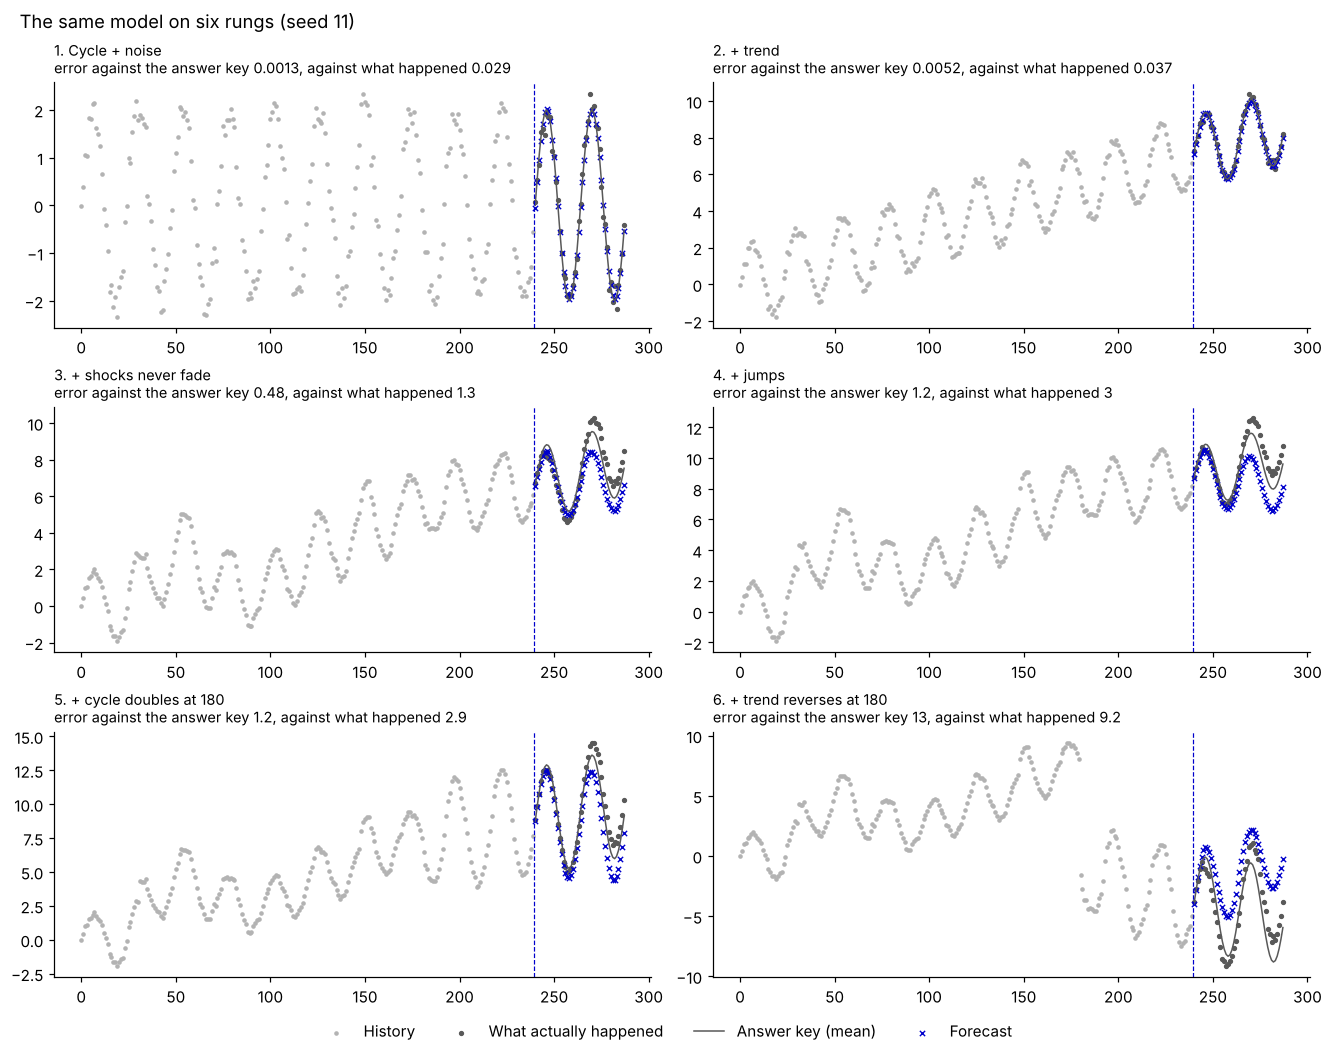

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9.5), layout='constrained')
for ax, rung, entry in zip(axes.flat, rungs, [c for c in ladder_run.cases if c.result.seed == 11]):
    draw(ax, entry, rung)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside lower center', ncol=4)
fig.suptitle('The same model on six rungs (seed 11)', x=0.01, ha='left')
plt.show()

On the first two rungs the forecast sits on the answer key. From rung 3 on it still follows the cycle but drifts away from the answer key as the horizon grows. On rung 6 the level drops by about 9 at step 180, because the generator measures the trend from step 0, so a new slope also shifts the level. The answer key keeps falling with the new trend; the forecast doesn't follow it down and ends about 6 above it.

## Three financial mechanisms, one at a time

| What you see | Technical name | Scenario family |
|---|---|---|
| The price moves smoothly most of the time, then suddenly jumps | Merton jump diffusion | `merton_jump_diffusion` |
| Calm and stormy periods: big moves come in clusters | GARCH | `garch` |
| The market switches between states you can't see, such as calm and crisis | Hidden Markov regimes | `markov_switching` |

A Merton jump moves the price by a percentage, unlike the level jumps above, which add a fixed amount. In GARCH and hidden regimes the rules never change: the volatility or the hidden state moves within fixed rules, unlike rungs 5 and 6. For hidden regimes, the answer key doesn't peek at the true state; it works out each regime's probability from the history, as a perfect forecaster would.

We forecast prices, log prices (on which a 5% move is the same size at any price) and returns (the change in log price from one step to the next), adding one mechanism at a time again. The model is the simplest there is: repeat the last value. The plots show seed 11.

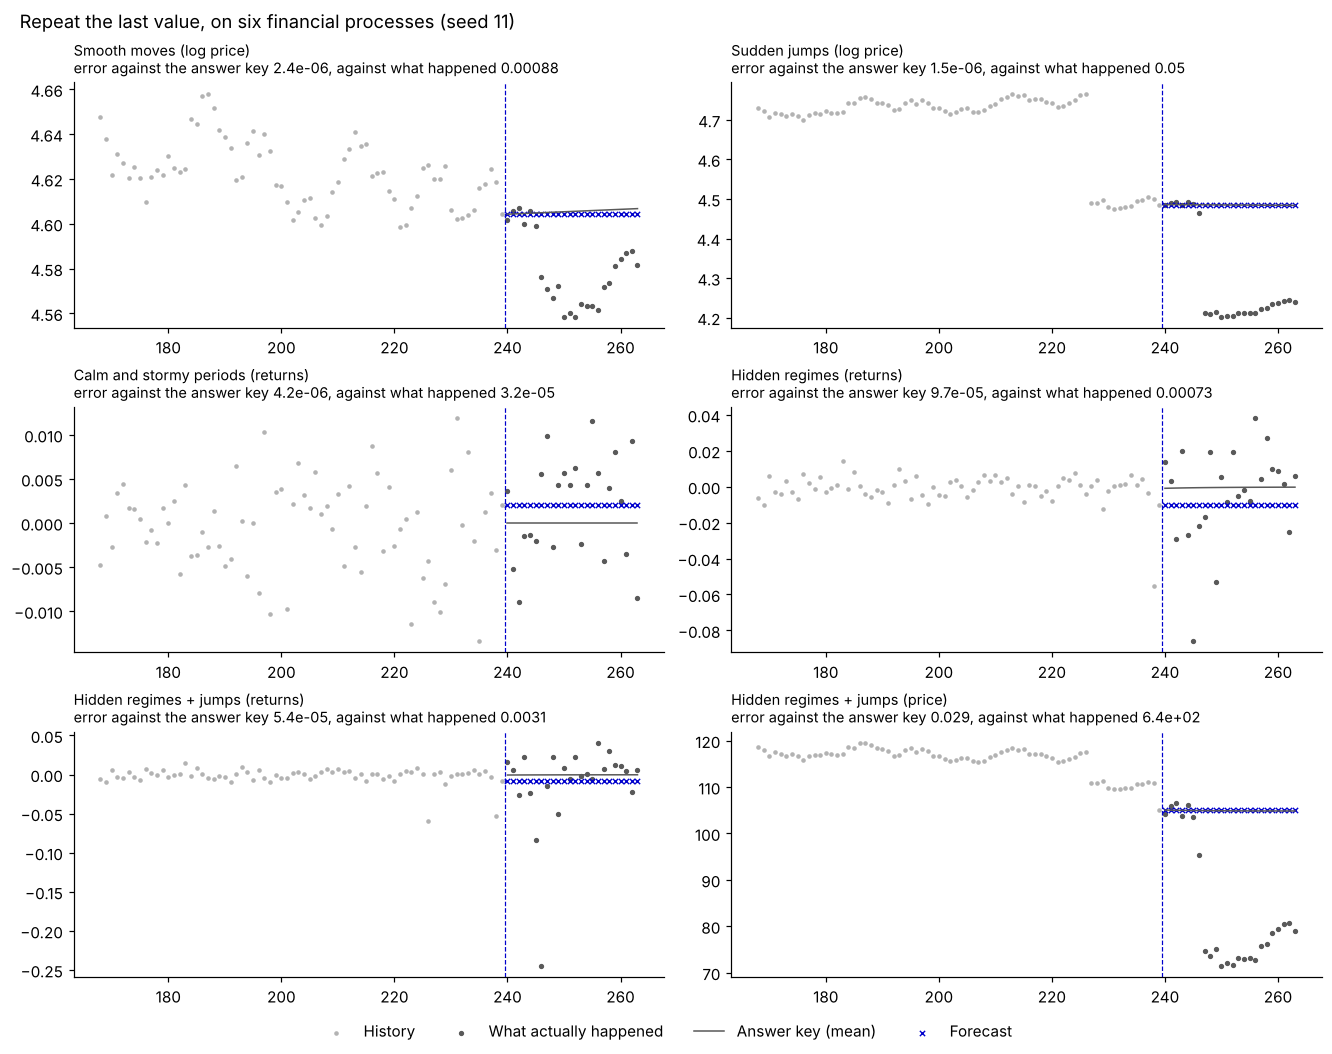

In [4]:
financial_specs = [
    {'kind': 'merton_jump_diffusion', 'parameters': {'mu': .04, 'sigma': .16, 'jump_rate': 0., 'output': 'log_price'}},
    {'kind': 'merton_jump_diffusion', 'parameters': {'mu': .04, 'sigma': .16, 'jump_rate': 6., 'jump_mean': -.05, 'jump_sigma': .12, 'output': 'log_price'}},
    {'kind': 'garch', 'parameters': {'omega': 3e-6, 'alpha': .15, 'beta': .8, 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [.04, -.10], 'regime_sigma': [.10, .60], 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [.04, -.10], 'regime_sigma': [.10, .60], 'regime_jump_rate': [3., 12.], 'regime_jump_mean': [0., -.06], 'regime_jump_sigma': [.03, .10], 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [.04, -.10], 'regime_sigma': [.10, .60], 'regime_jump_rate': [3., 12.], 'regime_jump_mean': [0., -.06], 'regime_jump_sigma': [.03, .10], 'output': 'price'}},
]
financial_names = ['Smooth moves (log price)', 'Sudden jumps (log price)', 'Calm and stormy periods (returns)',
                   'Hidden regimes (returns)', 'Hidden regimes + jumps (returns)', 'Hidden regimes + jumps (price)']
financial = [Scenario(context_length=240, horizon=24, **spec) for spec in financial_specs]
financial_run = Pipeline(NaiveForecaster(strategy='last')).run(financial, seeds=seeds)

fig, axes = plt.subplots(3, 2, figsize=(12, 9.5), layout='constrained')
for ax, name, entry in zip(axes.flat, financial_names, [c for c in financial_run.cases if c.result.seed == 11]):
    draw(ax, entry, name, last=72)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside lower center', ncol=4)
fig.suptitle('Repeat the last value, on six financial processes (seed 11)', x=0.01, ha='left')
plt.show()

On log prices and prices, repeating the last value hugs the answer key. On returns it repeats the latest return, a single noisy number, while the answer key sits near zero.

In the jump panel (top right), the log price drops sharply a few steps after the forecast starts, and the forecast misses badly. The price panel at the bottom shows the same kind of crash. Is that a bad model?

## Bad luck or a bad model?

Here is the jump process on all three seeds, scored both ways.

In [5]:
jump_cases = [c for c in financial_run.cases if c.scenario_index == 1]
luck = pd.DataFrame({'error against what happened': [c.result.metrics['mse'] for c in jump_cases],
                     'error against the answer key': [c.result.metrics['mean_reference_mse'] for c in jump_cases]},
                    index=pd.Index([c.result.seed for c in jump_cases], name='seed'))
assert luck.iloc[:, 0].max() > 20 * luck.iloc[:, 0].min()              # luck varies a lot by seed...
np.testing.assert_allclose(luck.iloc[:, 1], luck.iloc[0, 1], rtol=1e-6)  # ...the model's own error doesn't
display(luck.map('{:.2g}'.format))

,error against what happened,error against the answer key
seed,,
11,0.05,1.5e-06
22,0.00062,1.5e-06
33,0.0017,1.5e-06


Against what actually happened, seed 11 looks about eighty times worse than seed 22. Against the answer key, all three seeds score the same: repeating the last value misses only the small expected drift, which doesn't depend on the seed. Nobody could have predicted that jump. Scoring against the answer key tells bad luck apart from a bad model.

## A conversion bug: the right mean on the wrong scale

Now a mistake that no luck explains. A model forecasts log prices, and someone turns its mean into a price forecast by taking the exponential. But the average of the exponential is not the exponential of the average, and the gap grows with the uncertainty.

To see the bug without any model in the way, we generate one Merton process with monthly steps twice from the same seed, once as prices and once as log prices, and compare the two answer keys.

Last price: 67.72. After 12 months the answer key expects 71.91 (+6.2%); exp(expected log price) says 64.76 (-4.4%).
The buggy forecast: output checks PASS, error against the answer key 19.2.


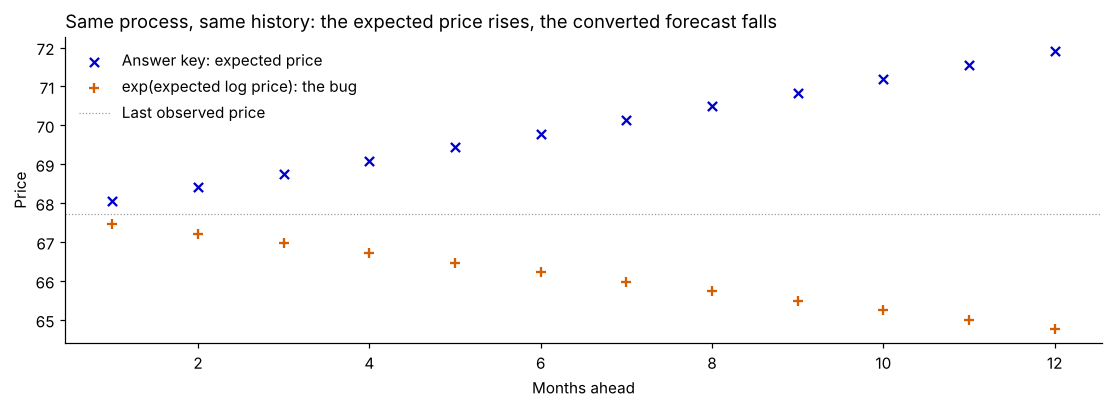

In [6]:
settings = {'mu': .06, 'sigma': .35, 'jump_rate': 2., 'jump_mean': -.08,
            'jump_sigma': .20, 'dt': 1/12}
price_case = Scenario('merton_jump_diffusion', 60, 12, {**settings, 'output': 'price'}).generate(seed=71)
log_case = Scenario('merton_jump_diffusion', 60, 12, {**settings, 'output': 'log_price'}).generate(seed=71)
np.testing.assert_allclose(np.log(price_case.task.context), log_case.task.context)  # same history, two units
expected_price = price_case.reference.mean[:, 0]
converted = np.exp(log_case.reference.mean[:, 0])
assert np.all(expected_price > converted)  # the conversion bug forecasts too low at every step
buggy = Forecast(index=price_case.task.future_index.copy(), point=converted[:, None],
                 target_names=price_case.task.target_names)
buggy_result = evaluate_forecast(price_case, buggy)
contract = next(d for d in buggy_result.diagnostics if d.name == 'forecast_contract')
assert contract.status == 'PASS'  # the bug sails through the output checks

last_price = price_case.task.context.iloc[-1, 0]
print(f'Last price: {last_price:.2f}. After 12 months the answer key expects {expected_price[-1]:.2f} '
      f'({expected_price[-1] / last_price - 1:+.1%}); exp(expected log price) says {converted[-1]:.2f} '
      f'({converted[-1] / last_price - 1:+.1%}).')
print(f"The buggy forecast: output checks {contract.status}, "
      f"error against the answer key {buggy_result.metrics['mean_reference_mse']:.1f}.")
fig, ax = plt.subplots(figsize=(10, 3.6), layout='constrained')
months = np.arange(1, 13)
ax.scatter(months, expected_price, marker='x', color=BLUE, label='Answer key: expected price')
ax.scatter(months, converted, marker='+', color='#D55E00', label='exp(expected log price): the bug')
ax.axhline(last_price, color='0.6', linewidth=0.8, linestyle=':', label='Last observed price')
ax.set(xlabel='Months ahead', ylabel='Price',
       title='Same process, same history: the expected price rises, the converted forecast falls')
ax.legend()
plt.show()

The answer key expects the price to grow 6.2% over the year: `mu = 0.06` is the price's own expected growth rate. The converted forecast says it falls 4.4%. Same process, same history, opposite direction. The buggy forecast has the right dates, shape and finite values, so it passes the output checks; only the error against the answer key gives it away.

## Which simple model wins depends on what you forecast

We score three simple models on the six processes, eight fresh seeds each: repeat the last value, predict the historical mean, or fit a Gaussian AR(1) (mean reversion: shocks fade). Each entry is a model's average error against the answer key (`mean_reference_mse`) divided by the best model's on that row, so 1 marks the winner.

In [7]:
candidates = {
    'Last value': Pipeline(NaiveForecaster(strategy='last')),
    'Historical mean': Pipeline(NaiveForecaster(strategy='mean')),
    'Fitted AR(1)': Pipeline(GaussianAR1Forecaster(n_samples=64, seed=901)),
}
model_errors = pd.DataFrame(
    {name: [np.mean([c.metrics['mean_reference_mse']
                     for c in candidate.test([scenario], seeds=range(6000, 6008)).cases])
            for scenario in financial]
     for name, candidate in candidates.items()},
    index=financial_names)
relative = model_errors.div(model_errors.min(axis=1), axis=0)
winner = model_errors.idxmin(axis=1)
on_levels = [0, 1, 5]  # log prices and prices; the other rows are returns
assert (winner.iloc[on_levels] == 'Last value').all()              # the last value wins on prices
assert (winner.drop(winner.index[on_levels]) == 'Historical mean').all()  # the mean wins on returns
display(relative.round(2).rename_axis('times the best error'))

,Last value,Historical mean,Fitted AR(1)
times the best error,,,
Smooth moves (log price),1.00,9450.56,107.13
Sudden jumps (log price),1.00,45240.90,1415.53
Calm and stormy periods (returns),215.07,1.00,1.01
Hidden regimes (returns),570.25,1.00,1.02
Hidden regimes + jumps (returns),466.00,1.00,1.02
Hidden regimes + jumps (price),1.00,10518.79,170.25


Prices behave like random walks (shocks never fade), so the last value wins on every price row, and the historical mean is thousands of times worse. Returns are mostly noise around a small average, so there the historical mean wins, the AR(1) comes within about 2%, and the last value is hundreds of times worse. A model that is right for one target can be badly wrong for the other, so a stress suite needs both.

## When the answer key is only approximate

Before trusting a check, look at how its answer key was made; TimeGym records it with each case. In the table, `analytic` means exact formulas, `exact_conditional` means possible futures are drawn from the true process, and `approximate_conditional` means they are drawn from an approximation of it.

Hidden regimes with jumps are the approximate case: to work out the regime, TimeGym must count how many jumps might have happened at each step, and it stops counting at some point (a truncated Poisson mixture). Scores still work, and the case still replays exactly. But an exact statistical test such as the covariance check (`covariance_dependence_check`) means nothing against an approximate answer key, so TimeGym returns **UNSUPPORTED**: not checked.

In [8]:
display(pd.DataFrame([{'process': name, 'answer key': reference.kind,
                       'possible futures drawn by': getattr(reference, 'sampler_kind', '')}
                      for name, reference in zip(financial_names,
                                                 [s.generate(seed=11).reference for s in financial])]
                     ).set_index('process'))

approximate = financial[-1].generate(seed=11).reference
verdict = covariance_dependence_check(approximate, approximate.sample(64, seed=700), n_calibration=39)
assert verdict.status == 'UNSUPPORTED'  # no exact test against an approximate answer key
print(f'{verdict.status}: {verdict.message}')

replayed = candidates['Last value'].test([financial[-1]], seeds=[11]).replay_case()
assert replayed.metadata['replay']['metrics_match'] and replayed.metadata['replay']['manifest_match']
print('The hidden regimes + jumps case still replays with the same settings and scores.')

,answer key,possible futures drawn by
process,,
Smooth moves (log price),analytic_conditional,
Sudden jumps (log price),analytic_moments_simulation,exact_conditional
Calm and stormy periods (returns),analytic_moments_simulation,exact_conditional
Hidden regimes (returns),analytic_moments_simulation,exact_conditional
Hidden regimes + jumps (returns),analytic_moments_simulation,approximate_conditional
Hidden regimes + jumps (price),analytic_moments_simulation,approximate_conditional


UNSUPPORTED: An approximate reference simulator cannot calibrate an exact conditional-law diagnostic.
The hidden regimes + jumps case still replays with the same settings and scores.


## Before you touch real data

1. Add one mechanism at a time, and note the rung where your model's error jumps.
2. Score against the answer key, on several seeds, so bad luck doesn't count as a bad model.
3. Check the scale of every output: an expected log price is not an expected price.
4. Keep some seeds, settings and combinations aside until the end, so you don't tune to the stress suite. Then freeze the pipeline and test it on unseen real data at several forecast origins.

**Try it.** Replace `lag_model` with `Pipeline(NaiveForecaster(strategy='last'))` and rerun the ladder to see which rung breaks a model that only repeats the last value. Or move `change_point` to 230, so the model sees just ten steps of the new rules.

**What this doesn't show.** These are synthetic series: doing well on them promises no accuracy, let alone profit, on real markets, and a stress suite can be overfit like any test set. Three or eight seeds are evidence, not proof. Where the answer key is approximate, its mean rests on numerically estimated regime probabilities, so don't read much into small differences there.

Reading: [the mechanisms and their literature](../docs/stress-cases.md) · [how the processes are built](../source/14_controlled_processes.ipynb).

Every family here also runs with several linked series. The next notebook asks what happens when they crash together.

**Next:** [Joint financial uncertainty](12_joint_financial_uncertainty.ipynb).